# The arcsine laws

> We shall encounter theoretical conclusions which not only are unexpected but actually come as a shock to intuition and common sense. — Feller

Three statistics of a random walk on [0, 1], each with the same, surprising, distribution.

In [1]:
%load_ext autoreload
%autoreload 2
    
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
from scipy import stats

from arcsine_laws import (
    ArcsineStatistic,
    donsker, 
    gaussian, 
    rademacher, 
    random_walk
)
from arcsine_laws.plots import (
    Colors,
    plot_histogram, 
    plot_paths, 
    plot_path_statistics, 
    plot_positive_intervals, 
    ArcsineStatistic
)

rng = np.random.default_rng(1729)

## Anatomy of a walk

For each walk we record:

* **time positive**: how long the walk spends above zero;
* **last zero**: when the walk last returns to zero;
* **maximum**: when the walk reaches its highest point.

Text(0.5, 1.0, 'One simple random walk, 50 steps')

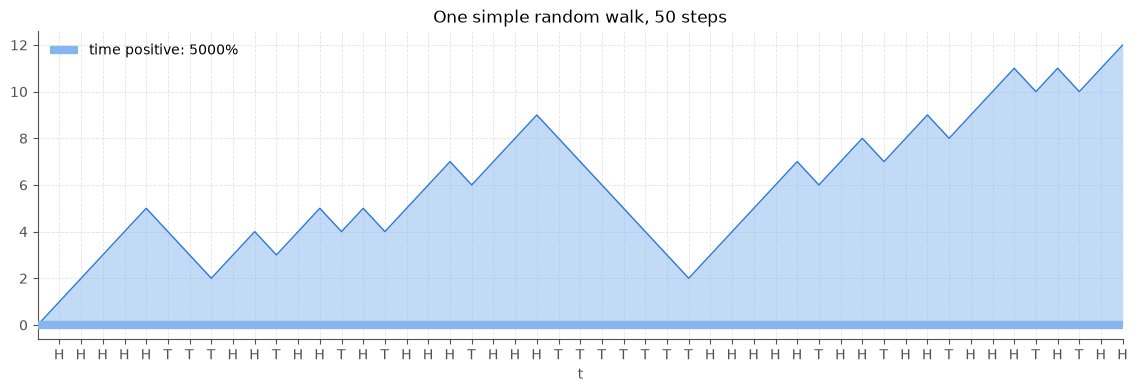

In [2]:
rng = np.random.default_rng(156)
walk = random_walk(50, rademacher(), rng=rng)

HT = {1: 'H', -1: 'T'}
flips = [HT.get(dx) for dx in walk.dx.flatten()]

fig, ax = plt.subplots(figsize=(14, 4))
plot_path_statistics(ax, walk, show=ArcsineStatistic.TIME_POSITIVE)
ax.set_xticks(np.arange(1, walk.t.max() + 1))
ax.set_xticklabels(flips)
ax.set_title(f"One simple random walk, {walk.n_steps} steps")

Text(0.5, 0, '')

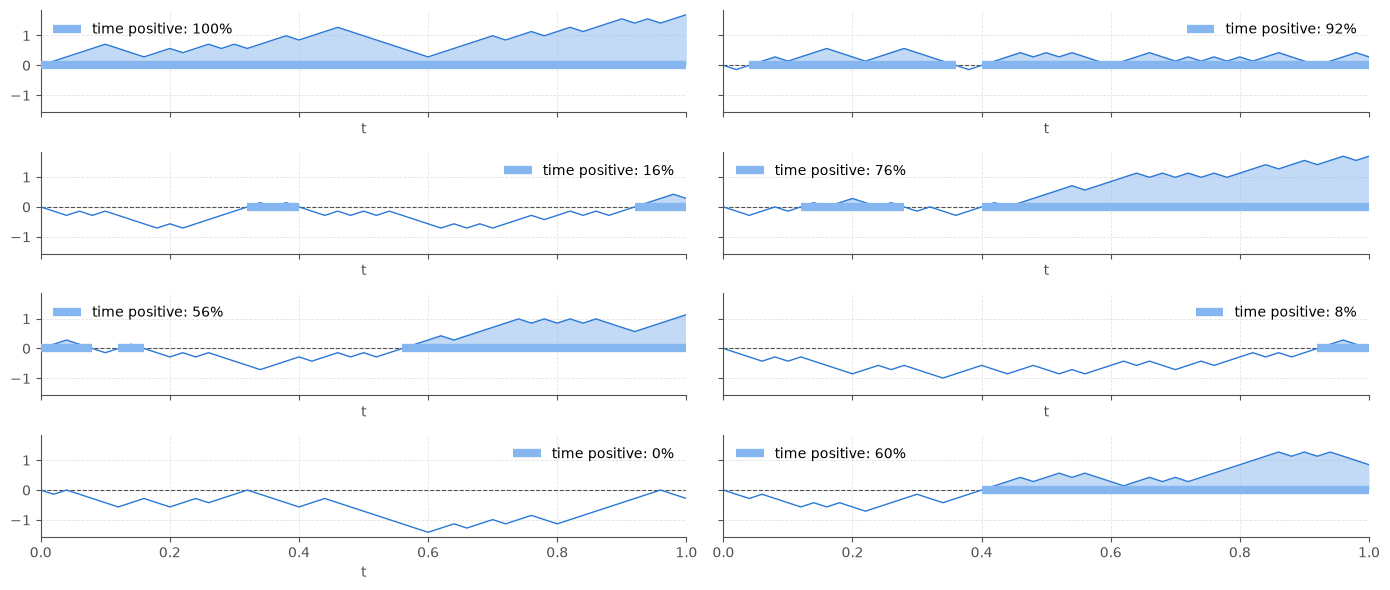

In [3]:
rng = np.random.default_rng(156)
walks = donsker(random_walk(50, rademacher(), n_paths=50, rng=rng))

fig, axs = plt.subplots(4, 2, figsize=(14, 6), sharex=True, sharey=True, layout="tight")
for i, ax in enumerate(axs.flatten()):
    plot_path_statistics(ax, walks, path=i, show=ArcsineStatistic.TIME_POSITIVE)
ax.set_xlabel("")

[]

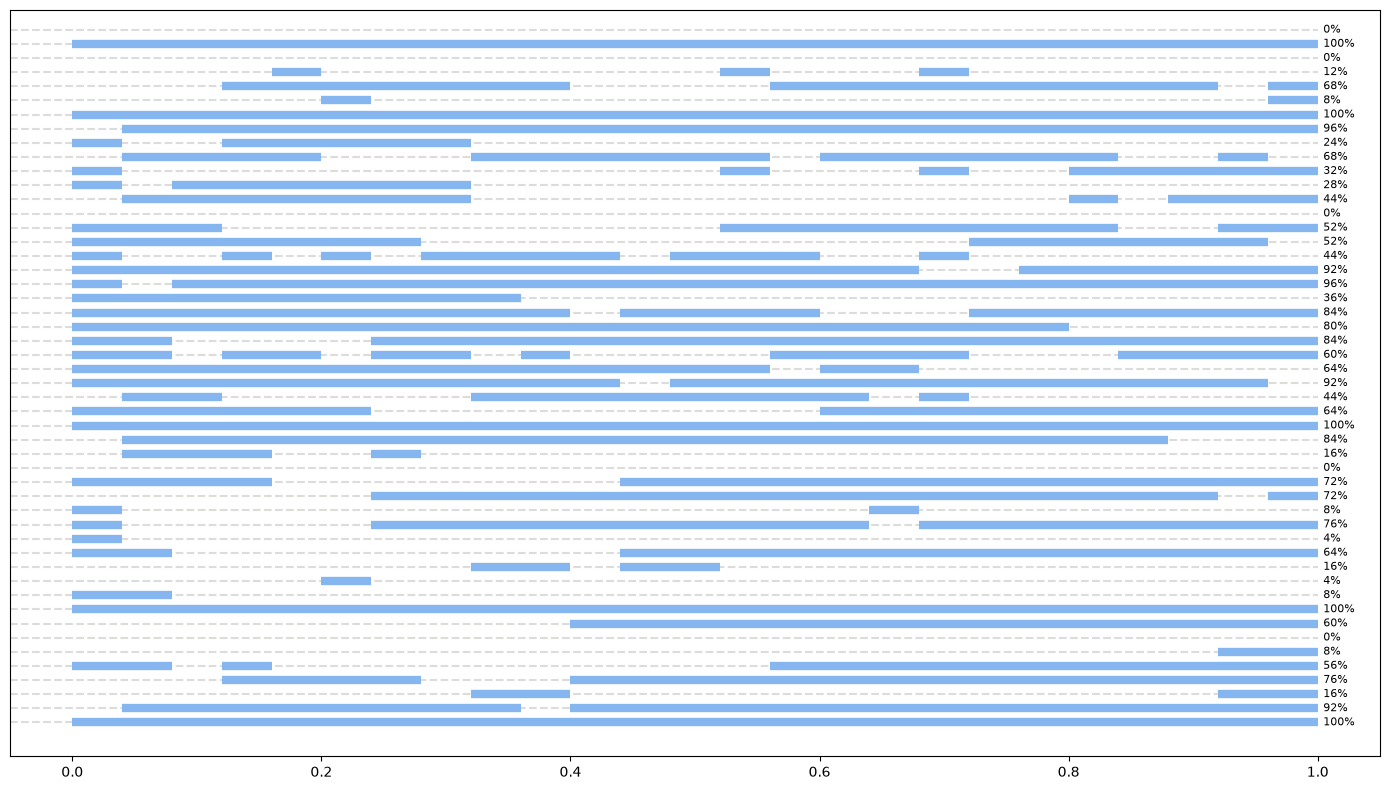

In [4]:
rng = np.random.default_rng(156)
walks = donsker(random_walk(50, rademacher(), n_paths=50, rng=rng))

fig, ax = plt.subplots(figsize=(14, 8), layout="tight")
for i, walk in enumerate(walks):
    time_positive = walk.time_positive()[0]
    plot_positive_intervals(ax, walk, y=i)
    ax.axhline(y=i, xmin=0.0, xmax=0.955, linestyle='--', alpha=0.2, color=Colors.INK)
    ax.annotate(
        f"{time_positive:2.0%}",
        (walk.t[-1], i),
        xytext=(4, 0),
        textcoords="offset points",
        verticalalignment="center",
        fontsize=8,
    )
    
ax.set_yticks([])

[]

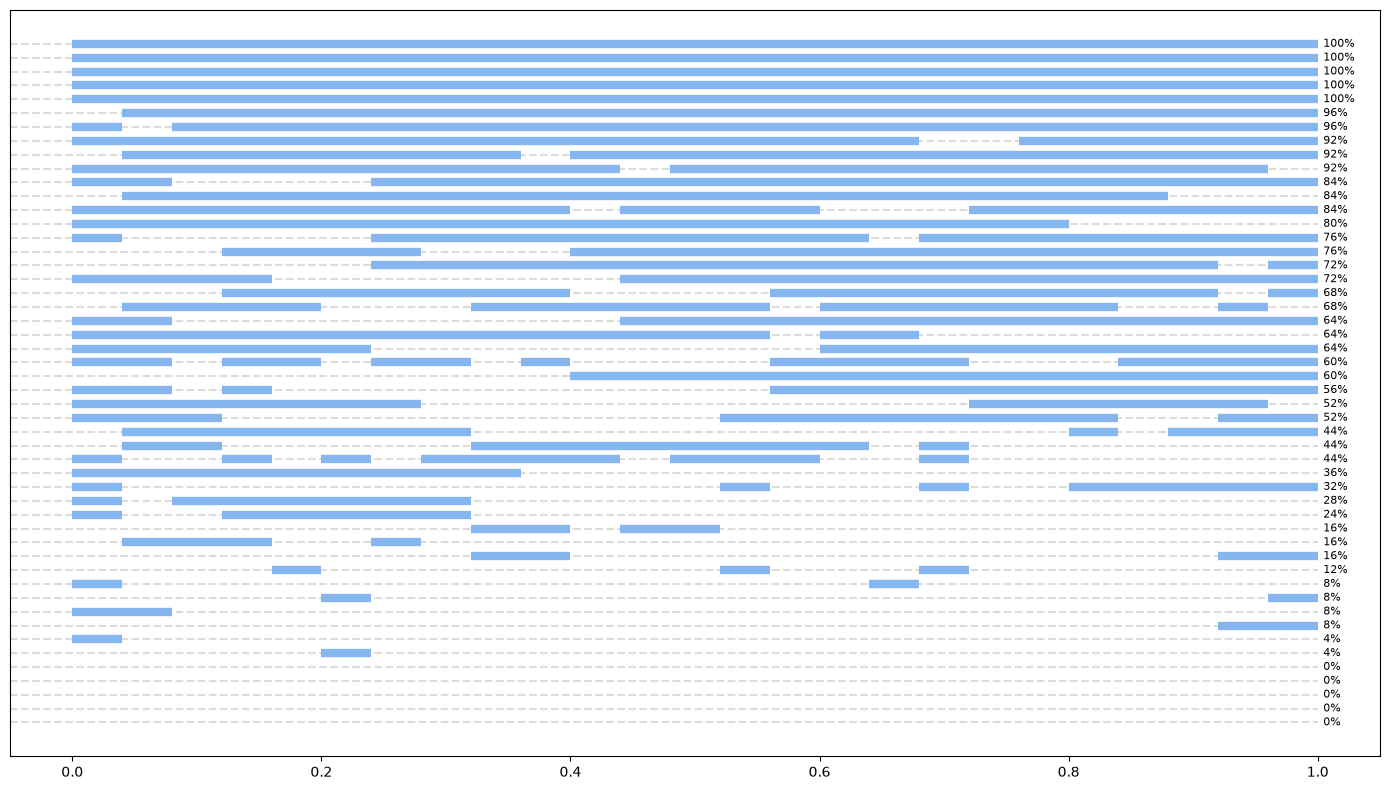

In [5]:
walks = walks.reorder(np.argsort(walks.time_positive()))

fig, ax = plt.subplots(figsize=(14, 8), layout="tight")
for i, walk in enumerate(walks):
    time_positive = walk.time_positive()[0]
    plot_positive_intervals(ax, walk, y=i)
    ax.axhline(y=i, xmin=0.0, xmax=0.955, linestyle='--', alpha=0.2, color=Colors.INK)
    ax.annotate(
        f"{time_positive:2.0%}",
        (walk.t[-1], i),
        xytext=(4, 0),
        textcoords="offset points",
        verticalalignment="center",
        fontsize=8,
    )
    
ax.set_yticks([])

Text(0.5, 1.0, 'Time Positive: 50 walks of length 50')

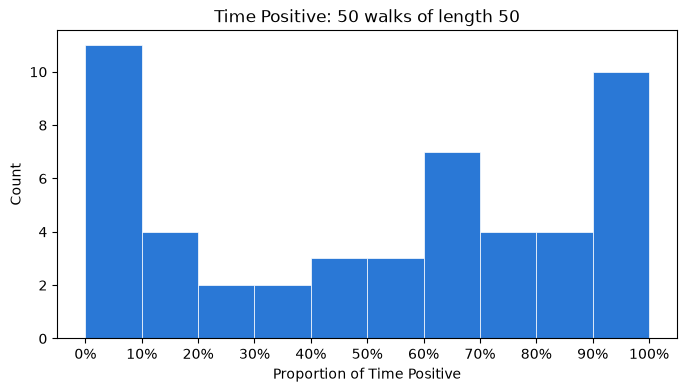

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
heights, edges, _ = ax.hist(
    walks.time_positive(),         
    color=Colors.BLUE,
    edgecolor="white",
    linewidth=0.5,
    label="simulated",
    bins=np.arange(0, 11) / 10
)
ax.set_xticks(np.arange(0, 11) / 10)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0))
ax.set_xlabel("Proportion of Time Positive")
ax.set_ylabel("Count")
ax.set_title(f"Time Positive: {walks.n_paths:,d} walks of length {walks.n_steps:,d}")

Text(0.5, 1.0, 'Time Positive: 20,000 walks of length 50')

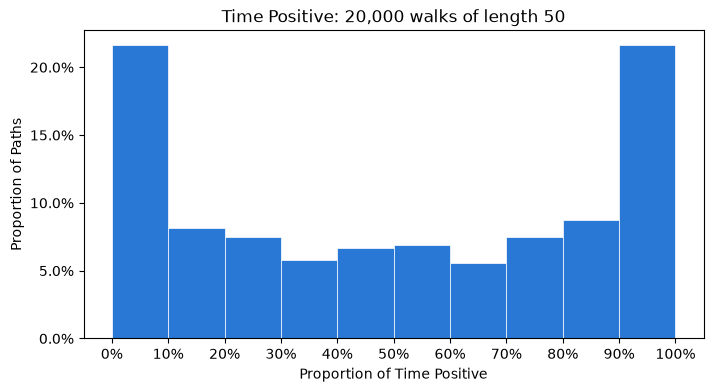

In [7]:
rng = np.random.default_rng(154)
walks = donsker(random_walk(50, rademacher(), n_paths=20_000, rng=rng))

fig, ax = plt.subplots(figsize=(8, 4))
heights, edges, _ = ax.hist(
    walks.time_positive(),         
    color=Colors.BLUE,
    edgecolor="white",
    linewidth=0.5,
    label="simulated",
    density=True
)
ax.set_xticks(np.arange(0, 11) / 10)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0))
ax.set_xlabel("Proportion of Time Positive")

# xmax=10 correctly sets the scale for bins of width 10%.
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=10.0))
ax.set_ylabel("Proportion of Paths")

ax.set_title(f"Time Positive: {walks.n_paths:,d} walks of length {walks.n_steps:,d}")

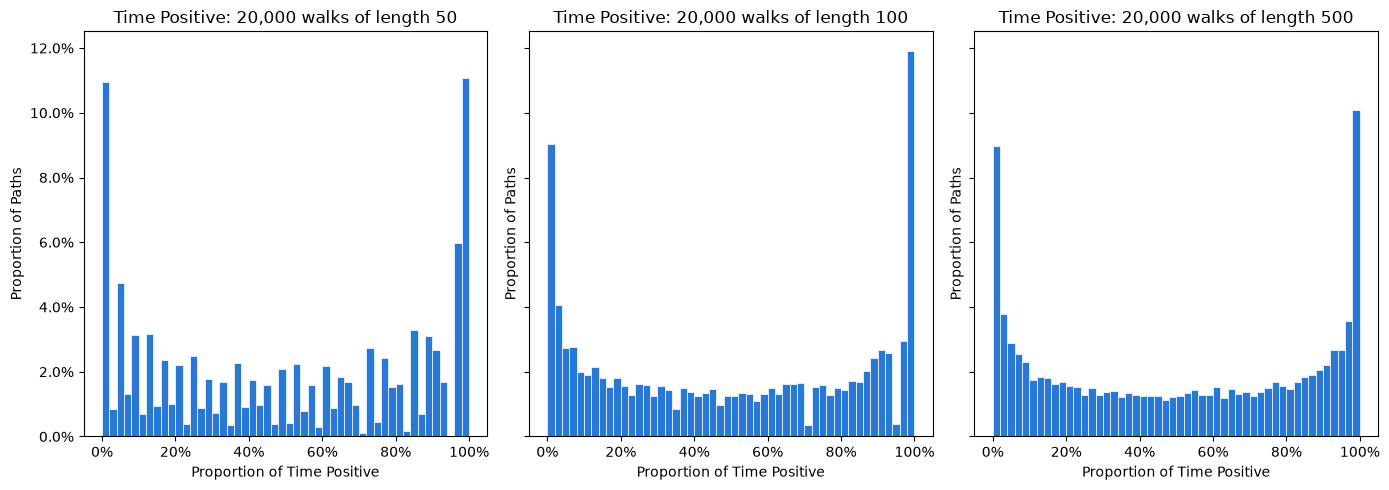

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(14, 5), sharey=True, layout="tight")


for ax, n_flips in zip(axs.flatten(), [50, 100, 500]): 
    
    walks = donsker(random_walk(n_flips, rademacher(), n_paths=20_000, rng=rng))
    heights, edges, _ = ax.hist(
        walks.time_positive(),         
        color=Colors.BLUE,
        edgecolor="white",
        linewidth=0.5,
        label="simulated",
        density=True,
        bins=50
    )
    ax.set_xticks(np.arange(0, 11, 2) / 10)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0))
    ax.set_xlabel("Proportion of Time Positive")
    
    # xmax=10 correctly sets the scale for bins of width 10%.
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=50.0))
    ax.set_ylabel("Proportion of Paths")
    
    ax.set_title(f"Time Positive: {walks.n_paths:,d} walks of length {walks.n_steps:,d}")

/var/folders/50/gr_764fj06b9bndhn5mc84080000gn/T/ipykernel_95133/3970371539.py:20: RuntimeWarning: divide by zero encountered in divide
  1/(np.pi * np.sqrt(ts * (1 - ts))),


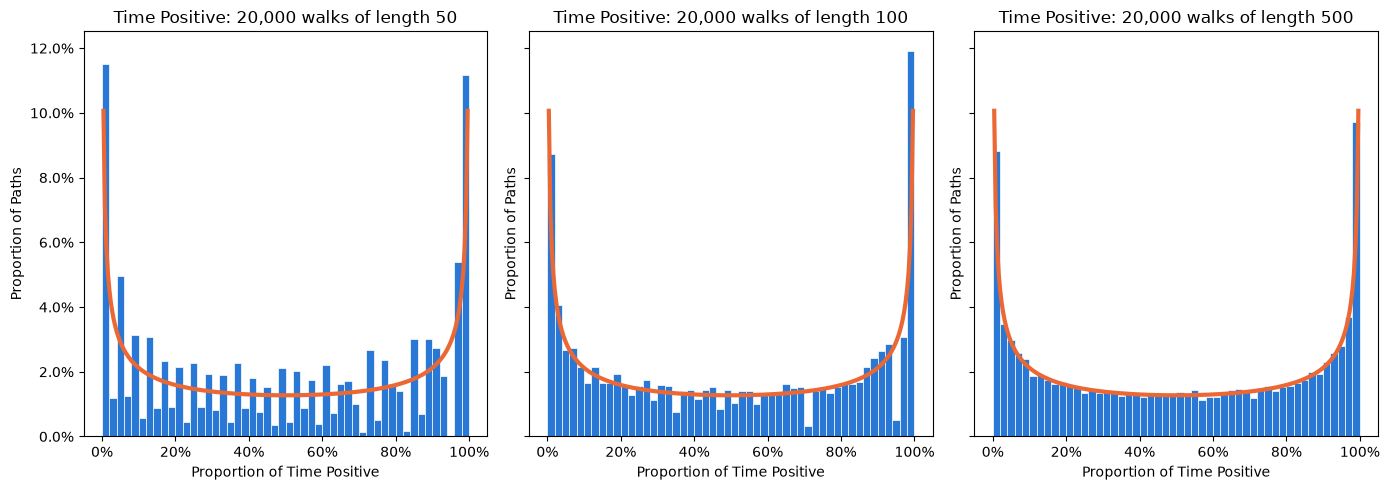

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(14, 5), sharey=True, layout="tight")


for ax, n_flips in zip(axs.flatten(), [50, 100, 500]): 
    walks = donsker(random_walk(n_flips, rademacher(), n_paths=20_000, rng=rng))
    
    heights, edges, _ = ax.hist(
        walks.time_positive(),         
        color=Colors.BLUE,
        edgecolor="white",
        linewidth=0.5,
        label="simulated",
        density=True,
        bins=50
    )

    ts = np.linspace(0.0, 1.0, num=250)
    ax.plot(
        ts, 
        1/(np.pi * np.sqrt(ts * (1 - ts))),
        linewidth=3,
        color=Colors.ORANGE
    )
    
    ax.set_xticks(np.arange(0, 11, 2) / 10)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0))
    ax.set_xlabel("Proportion of Time Positive")
    
    # xmax=10 correctly sets the scale for bins of width 10%.
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=50.0))
    ax.set_ylabel("Proportion of Paths")
    
    ax.set_title(f"Time Positive: {walks.n_paths:,d} walks of length {walks.n_steps:,d}")

/var/folders/50/gr_764fj06b9bndhn5mc84080000gn/T/ipykernel_95133/3611031830.py:4: RuntimeWarning: divide by zero encountered in divide
  return 1/(np.pi * np.sqrt(ts * (1 - ts)))


Text(0.5, 1.0, 'Arcsine Law of Time Spent Postitive')

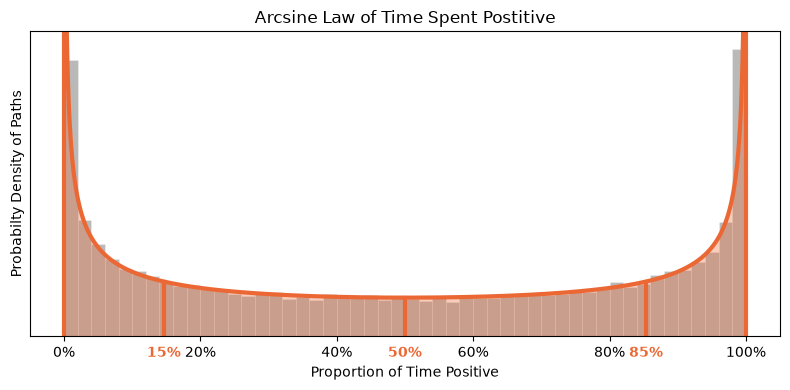

In [15]:
fig, ax = plt.subplots(figsize=(8, 4), layout="tight")

def f(ts): 
    return 1/(np.pi * np.sqrt(ts * (1 - ts)))

def F(ts):
    return (2 / np.pi) * np.arcsin(np.sqrt(ts))

def Q(qs):
    return np.sin((np.pi / 2) * qs)**2

ax.hist(
        walks.time_positive(),         
        color=Colors.INK,
        edgecolor="white",
        linewidth=0.5,
        label="simulated",
        density=True,
        bins=50,
        alpha=0.4
    )

ts = np.linspace(0.0, 1.0, num=1000)
fs = np.clip(f(ts), a_max=100.0, a_min=None)
ax.plot(
    ts, 
    fs,
    linewidth=3,
    color=Colors.ORANGE
)
ax.fill_between(ts, fs, color=Colors.ORANGE, alpha=0.33)

quantiles = np.array([Q(0.0), Q(0.25), Q(0.5), Q(0.75), Q(1)])
densities = np.clip(f(quantiles), a_max=100.0, a_min=None)
for q, d in zip(quantiles, densities):
    ax.plot([q, q], [d, 0], color=Colors.ORANGE, linewidth=3)
for q, d in zip(quantiles[1:-1], densities[1:-1]):
    ax.annotate(
        f"{q:2.0%}",
        xy=(q, 0),
        xycoords=ax.get_xaxis_transform(),
        # Same offset and size as the tick labels: tick length plus padding.
        xytext=(0, -(plt.rcParams["xtick.major.size"] + plt.rcParams["xtick.major.pad"])),
        textcoords="offset points",
        horizontalalignment="center",
        verticalalignment="top",
        fontsize=plt.rcParams["xtick.labelsize"],
        color=Colors.ORANGE,
        fontweight="bold",
    )

ax.set_xticks(np.arange(0, 11, 2) / 10)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0))
ax.set_xlabel("Proportion of Time Positive")

ax.set_yticks([])
ax.set_ylabel("Probabilty Density of Paths")
ax.set_ybound(lower=0.0, upper=5.0)

ax.set_title(f"Arcsine Law of Time Spent Postitive")

One statistic at a time, on the same walk.

Text(0.5, 0, '')

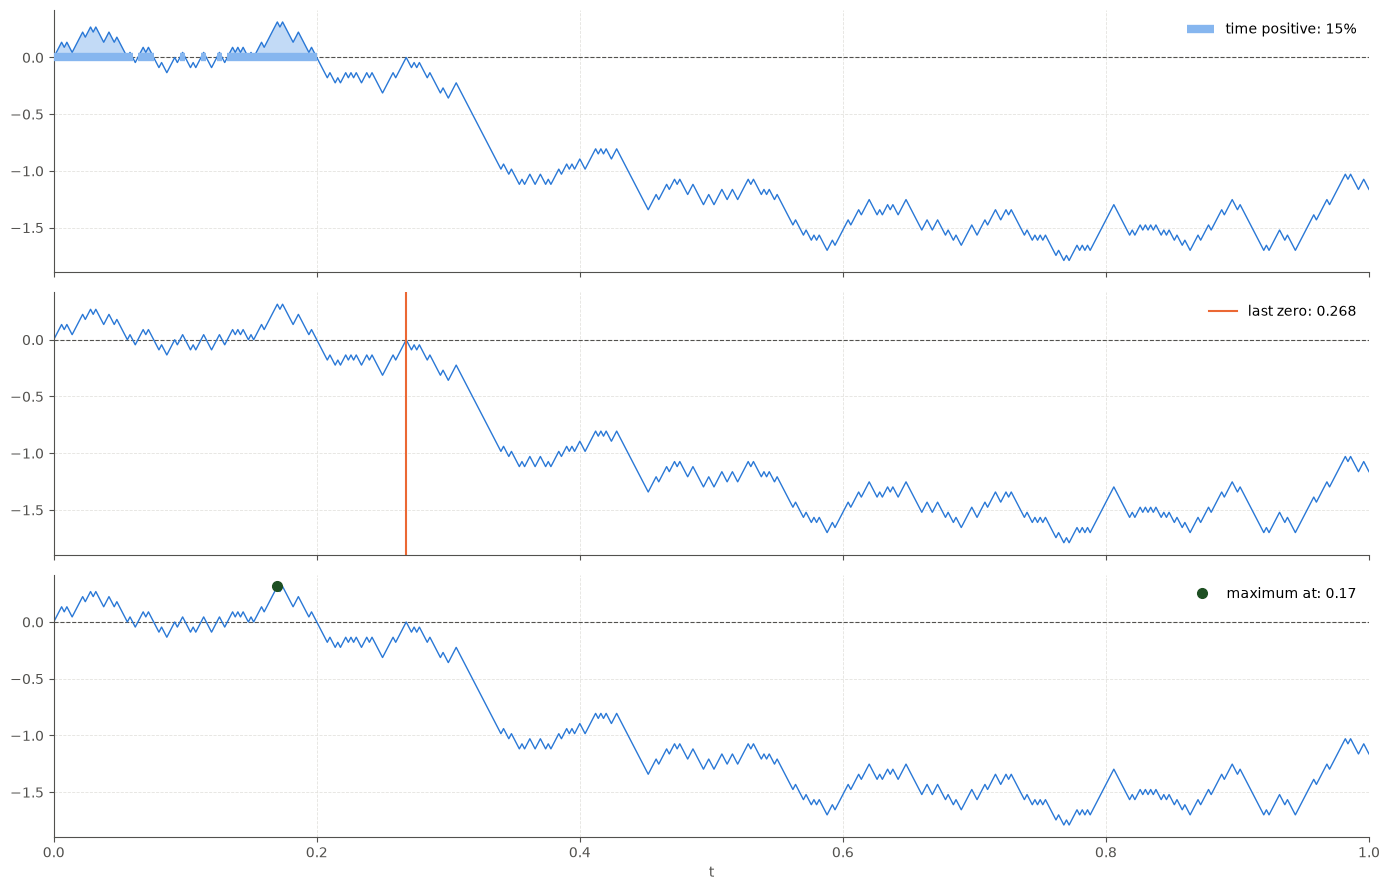

In [11]:
fig, axs = plt.subplots(3, 1, figsize=(14, 9), sharex=True, layout="tight")
for ax, statistic in zip(axs, ArcsineStatistic):
    plot_path_statistics(ax, walks, path=2, show=statistic)
axs[0].set_xlabel("")
axs[1].set_xlabel("")

## The arcsine laws

Simulate many walks and histogram each statistic. Intuition says the walk should spend about half its time ahead, and keep returning to zero right up to the end. Instead all three statistics pile up at the *ends* of the interval, following the arcsine density

    1 / (pi * sqrt(x * (1 - x)))

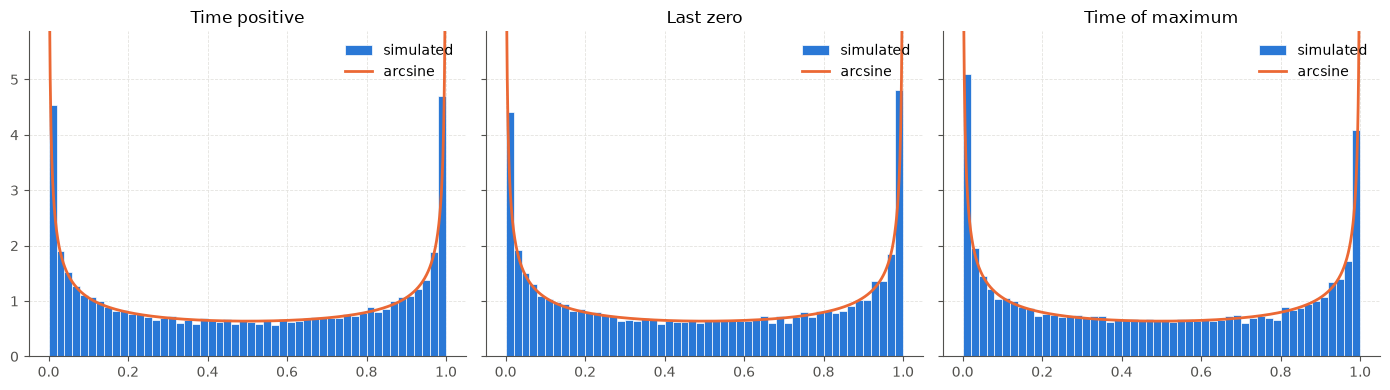

In [12]:
walks = donsker(random_walk(1000, rademacher(), n_paths=20_000, rng=rng))

statistics = {
    "Time positive": walks.time_positive(),
    "Last zero": walks.last_zero(),
    "Time of maximum": walks.t[walks.argmax()],
}

fig, axs = plt.subplots(1, 3, figsize=(14, 4), sharey=True, layout="tight")
for ax, (name, values) in zip(axs, statistics.items()):
    plot_histogram(ax, values, reference=stats.arcsine(), reference_label="arcsine")
    ax.set_title(name)

## How lopsided?

Compare a walk that spends nearly all its time on one side with one that splits its time fairly evenly.

In [13]:
time_positive = statistics["Time positive"]
lopsided = np.mean((time_positive < 0.1) | (time_positive > 0.9))
balanced = np.mean((time_positive > 0.4) & (time_positive < 0.6))
print(f"Over 90% of the time on one side: {lopsided:.1%}")
print(f"Between 40% and 60% of the time positive: {balanced:.1%}")

Over 90% of the time on one side: 41.1%
Between 40% and 60% of the time positive: 12.5%


## Brownian motion

The same three statistics for Brownian motion, as Gaussian walks on a fine grid.

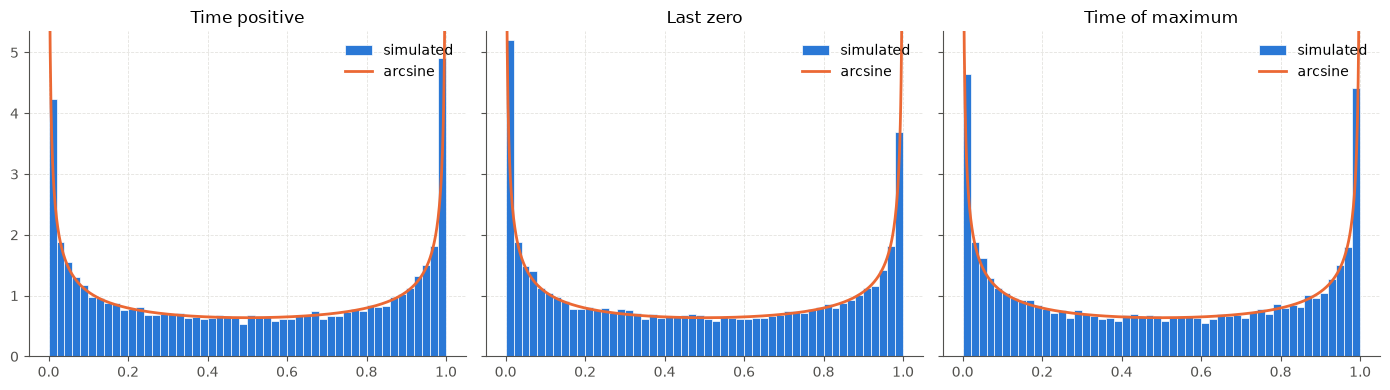

In [14]:
n_steps = 1024
bm = random_walk(n_steps, gaussian(variance=1/n_steps), n_paths=20_000, dt=1/n_steps, rng=rng)

statistics = {
    "Time positive": bm.time_positive(),
    "Last zero": bm.last_zero(),
    "Time of maximum": bm.t[bm.argmax()],
}

fig, axs = plt.subplots(1, 3, figsize=(14, 4), sharey=True, layout="tight")
for ax, (name, values) in zip(axs, statistics.items()):
    plot_histogram(ax, values, reference=stats.arcsine(), reference_label="arcsine")
    ax.set_title(name)